In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Read the data from csv file.
data = pd.read_csv("student_data.csv")

# Call the first five data
print(data.head())

   Unnamed: 0  Gender EthnicGroup          ParentEduc     LunchType TestPrep  \
0           0  female         NaN   bachelor's degree      standard     none   
1           1  female     group C        some college      standard      NaN   
2           2  female     group B     master's degree      standard     none   
3           3    male     group A  associate's degree  free/reduced     none   
4           4    male     group C        some college      standard     none   

  ParentMaritalStatus PracticeSport IsFirstChild  NrSiblings TransportMeans  \
0             married     regularly          yes         3.0     school_bus   
1             married     sometimes          yes         0.0            NaN   
2              single     sometimes          yes         4.0     school_bus   
3             married         never           no         1.0            NaN   
4             married     sometimes          yes         0.0     school_bus   

  WklyStudyHours  MathScore  ReadingScore  W

In [3]:
# Gives all the statistics values.
data.describe()

,Unnamed: 0,NrSiblings,MathScore,ReadingScore,WritingScore
count,30641.000000,29069.000000,30641.000000,30641.000000,30641.000000
mean,499.556607,2.145894,66.558402,69.377533,68.418622
std,288.747894,1.458242,15.361616,14.758952,15.443525
min,0.000000,0.000000,0.000000,10.000000,4.000000
25%,249.000000,1.000000,56.000000,59.000000,58.000000
50%,500.000000,2.000000,67.000000,70.000000,69.000000
75%,750.000000,3.000000,78.000000,80.000000,79.000000
max,999.000000,7.000000,100.000000,100.000000,100.000000


## Checking column names.

In [4]:
print(data.columns)

Index(['Unnamed: 0', 'Gender', 'EthnicGroup', 'ParentEduc', 'LunchType',
       'TestPrep', 'ParentMaritalStatus', 'PracticeSport', 'IsFirstChild',
       'NrSiblings', 'TransportMeans', 'WklyStudyHours', 'MathScore',
       'ReadingScore', 'WritingScore'],
      dtype='object')


In [5]:
# Quickly summarize the dataframe.
print(data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30641 entries, 0 to 30640
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Unnamed: 0           30641 non-null  int64  
 1   Gender               30641 non-null  object 
 2   EthnicGroup          28801 non-null  object 
 3   ParentEduc           28796 non-null  object 
 4   LunchType            30641 non-null  object 
 5   TestPrep             28811 non-null  object 
 6   ParentMaritalStatus  29451 non-null  object 
 7   PracticeSport        30010 non-null  object 
 8   IsFirstChild         29737 non-null  object 
 9   NrSiblings           29069 non-null  float64
 10  TransportMeans       27507 non-null  object 
 11  WklyStudyHours       29686 non-null  object 
 12  MathScore            30641 non-null  int64  
 13  ReadingScore         30641 non-null  int64  
 14  WritingScore         30641 non-null  int64  
dtypes: float64(1), int64(4), object(10)


In [6]:
# Finding the null value.
data.isnull().sum()

Unnamed: 0                0
Gender                    0
EthnicGroup            1840
ParentEduc             1845
LunchType                 0
TestPrep               1830
ParentMaritalStatus    1190
PracticeSport           631
IsFirstChild            904
NrSiblings             1572
TransportMeans         3134
WklyStudyHours          955
MathScore                 0
ReadingScore              0
WritingScore              0
dtype: int64

## Drop unnamed column
As the unnamed column is of no use, So deleting the column.

In [7]:
data = data.drop("Unnamed: 0" , axis=1)
print(data.head())

   Gender EthnicGroup          ParentEduc     LunchType TestPrep  \
0  female         NaN   bachelor's degree      standard     none   
1  female     group C        some college      standard      NaN   
2  female     group B     master's degree      standard     none   
3    male     group A  associate's degree  free/reduced     none   
4    male     group C        some college      standard     none   

  ParentMaritalStatus PracticeSport IsFirstChild  NrSiblings TransportMeans  \
0             married     regularly          yes         3.0     school_bus   
1             married     sometimes          yes         0.0            NaN   
2              single     sometimes          yes         4.0     school_bus   
3             married         never           no         1.0            NaN   
4             married     sometimes          yes         0.0     school_bus   

  WklyStudyHours  MathScore  ReadingScore  WritingScore  
0            < 5         71            71            74  


## Gender distribution.
Counting the number of male and female in the dataframe.  
Using count plot.

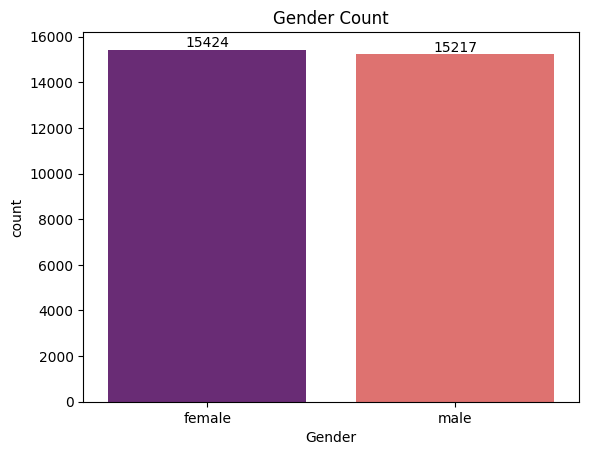

In [8]:
# figsize = To set the size of graph before plotting.
# plt.figure(figsize= (4,3))

# Changing the color of both bar
# sns.countplot(x= "Gender", data=data, color="green")

# Changing the color of each bar use palette along with hue.
# hue : Tells seaborn to use different color based on the values.
# ax = Axes Object.


ax = sns.countplot(x= "Gender", hue="Gender", data=data, palette="magma")

# Add labels(Counting number) on the top of bar. 
for container in ax.containers:
    ax.bar_label(container)      

plt.title("Gender Count")
plt.show()

*** 
From the above chart we have analysed that, number of female is more than the number of males. 
***

### Determining Whether the parent education matters score.

In [11]:
# groupby() = Groups similar values together 
# agg() =lets you perform calculations at once on grouped data.

gb = data.groupby("ParentEduc").agg({"MathScore":'mean', "ReadingScore" : 'mean',"WritingScore" : 'mean'})

print(gb)

                    MathScore  ReadingScore  WritingScore
ParentEduc                                               
associate's degree  68.365586     71.124324     70.299099
bachelor's degree   70.466627     73.062020     73.331069
high school         64.435731     67.213997     65.421136
master's degree     72.336134     75.832921     76.356896
some college        66.390472     69.179708     68.501432
some high school    62.584013     65.510785     63.632409


## Making Heatmap

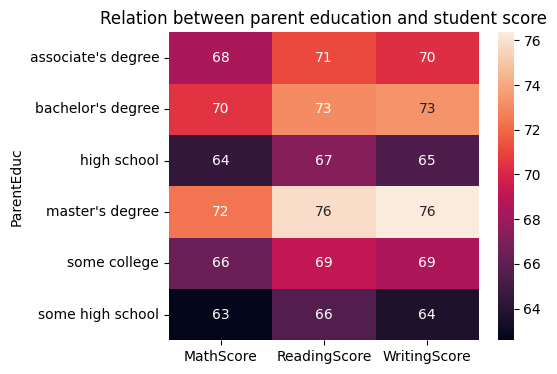

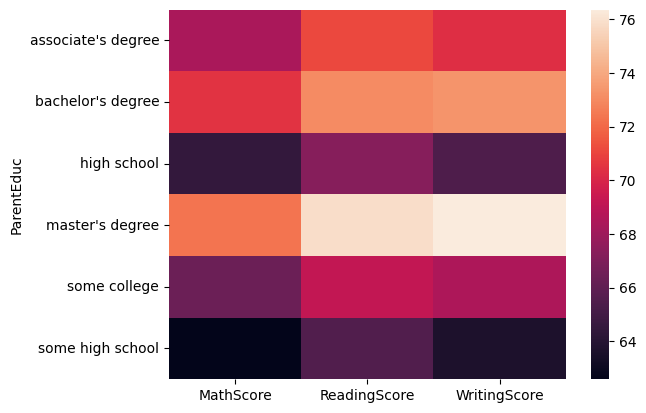

In [37]:
plt.figure(figsize=(5,4))
# annot = Annotation
# Add text label on the graph.
sns.heatmap(gb, annot=True)
plt.title("Relation between parent education and student score")
plt.show()

# See the difference between graph with and without annot
sns.heatmap(gb)
plt.show()

From the above chart, we can say that education of the parents have good impact on their scores

## Analysis based on marital status

In [30]:
marital = data.groupby("ParentMaritalStatus").agg({"MathScore":'mean', "ReadingScore" : 'mean',"WritingScore" : 'mean'})
print("\n\n" ,marital)



                      MathScore  ReadingScore  WritingScore
ParentMaritalStatus                                       
divorced             66.691197     69.655011     68.799146
married              66.657326     69.389575     68.420981
single               66.165704     69.157250     68.174440
widowed              67.368866     69.651438     68.563452


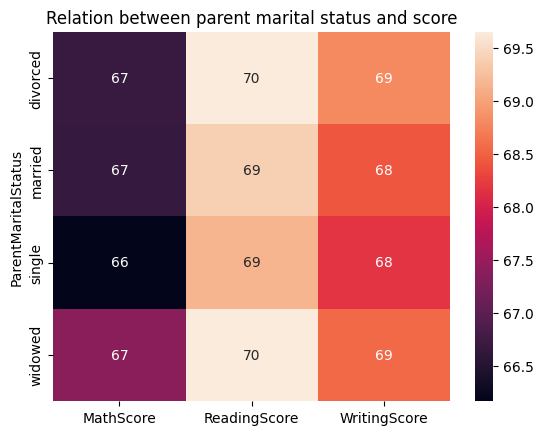

In [38]:
sns.heatmap(marital, annot=True)
plt.title("Relation between parent marital status and score")
plt.show()

As Parent marital status doesnot impact student's score.

## Analysis based on PracticeSport

In [ ]:
# print(data)
sport = data.groupby("PracticeSport").agg({"MathScore":'mean', "ReadingScore" : 'mean',"WritingScore" : 'mean'})

print(sport)

               MathScore  ReadingScore  WritingScore
PracticeSport                                       
never          64.171079     68.337662     66.522727
regularly      67.839155     69.943019     69.604003
sometimes      66.274831     69.241307     68.072438


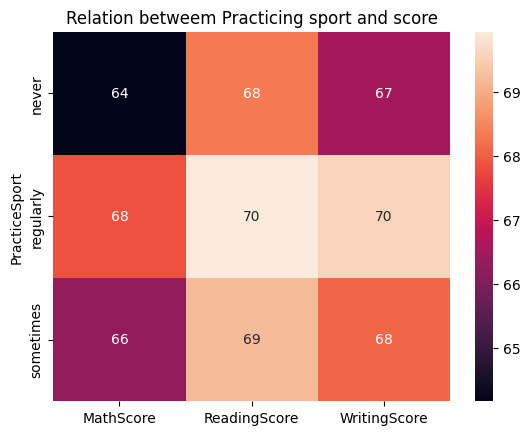

In [62]:
sns.heatmap(sport, annot=True)
plt.title("Relation betweem Practicing sport and score")
plt.show()


From above chart we can conclude that practicing sports regularly sharpes the mind and have good impart on their score.

## Box Plot

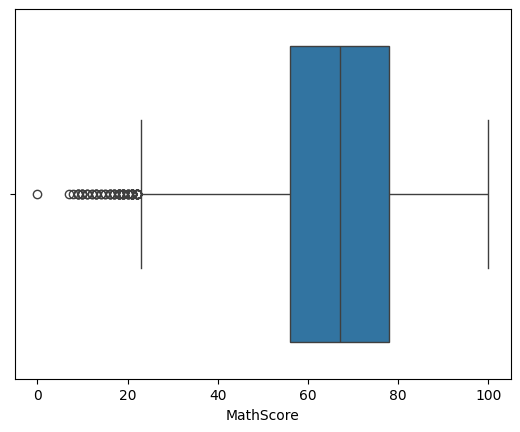

In [43]:
sns.boxplot(data=data, x="MathScore")
plt.show()

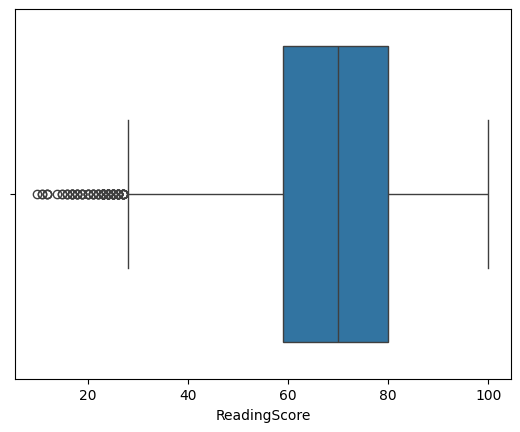

In [44]:
sns.boxplot(data=data, x="ReadingScore")
plt.show()

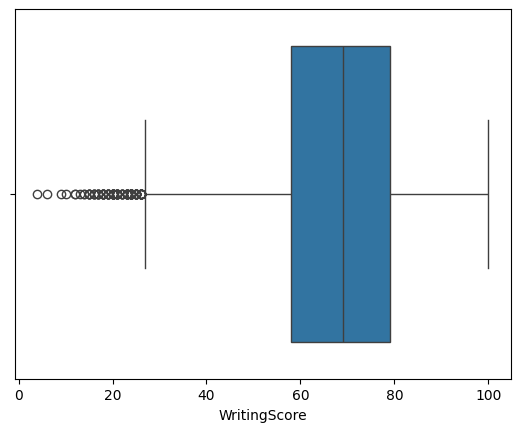

In [45]:
sns.boxplot(data=data, x="WritingScore")
plt.show()

So, From the above three box plot we can say that math is quite difficult subject to bring good score and only in math there is at least one who got 0.

## Getting Unique values

In [46]:
print(data["EthnicGroup"].unique())

[nan 'group C' 'group B' 'group A' 'group D' 'group E']


## Distribution of Ethnic Groups

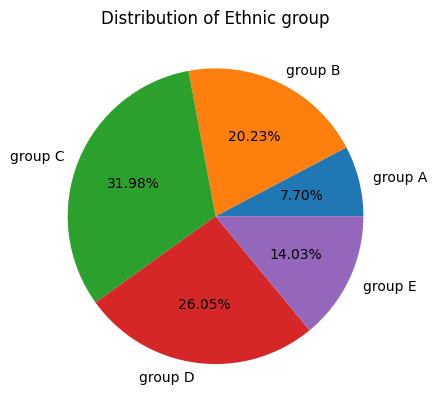

In [61]:
# loc =  Selecting rows and columns by their labels(names).
groupA = data.loc[(data["EthnicGroup"] == "group A")].count()
groupB = data.loc[(data["EthnicGroup"] == "group B")].count()
groupC = data.loc[(data["EthnicGroup"] == "group C")].count()
groupD = data.loc[(data["EthnicGroup"] == "group D")].count()
groupE = data.loc[(data["EthnicGroup"] == "group E")].count()

l = ["group A", "group B", "group C", "group D", "group E"]
mlist = [groupA["EthnicGroup"], groupB["EthnicGroup"],groupC["EthnicGroup"],groupD["EthnicGroup"], groupE["EthnicGroup"]]


# autopact = auto percetage
#  Automatically displays the percentage value on each slice of pie chart.

plt.pie(mlist, labels= l, autopct = "%.2f%%")
plt.title("Distribution of Ethnic group")
plt.show()


## Count Plot

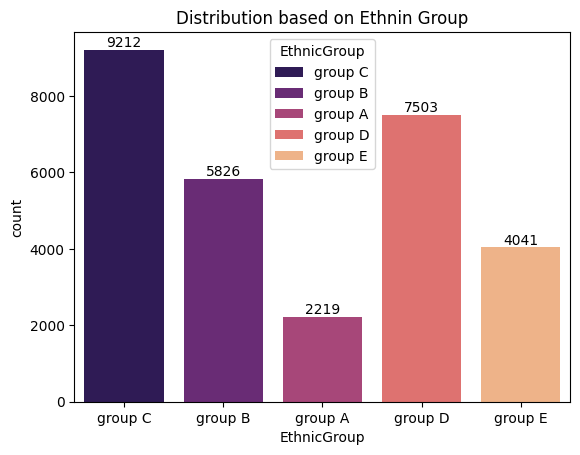

In [ ]:
ax = sns.countplot(data=data, x="EthnicGroup", hue="EthnicGroup", palette="magma")

for container in ax.containers:
    ax.bar_label(container)

plt.title("Distribution based on Ethnin Group")
plt.show()